# ML3 — Gợi ý sản phẩm (Item-based CF / Content-based) và kiểm chứng

**Loại bài toán:** recommendation / khám phá quan hệ mua hàng.

**Vì sao cần "kiểm chứng" thay vì cứ làm:** dữ liệu chỉ có **15 sản phẩm**, chỉ có lịch sử mua (không có click/view/co-cart). Collaborative filtering có thể không học được gì, nên notebook này đặt câu hỏi *"mô hình có thật sự hơn baseline không?"* trước khi kết luận.

**Thiết kế đánh giá**
- Tác vụ: **sản phẩm *mới* tiếp theo** — không gợi ý lại hàng khách đã mua.
- Hai giao thức, đều chống rò rỉ (độ phổ biến và độ tương đồng chỉ tính từ dữ liệu train):
  - **A – leave-last-out:** giữ lại đơn cuối của mỗi khách (đúng như tài liệu).
  - **B – theo thời gian:** train < 2025-01-01, mục tiêu là các sản phẩm khách mua mới từ 2025.
- Chỉ tính trên khách đủ điều kiện (có lịch sử và mặt hàng test là hàng chưa từng mua).
- Metric: **HitRate@K, Recall@K, catalog coverage**. Baseline: **MostPopular** và **Random**.
- Kết luận "vượt baseline" **chỉ khi** khoảng tin cậy 95% (bootstrap ghép cặp) của chênh lệch HitRate@3 > 0.

> Các hàm được sao nguyên văn từ `ml3_recommender.py`.

In [18]:
from __future__ import annotations
import sys, json
from pathlib import Path
from datetime import datetime, timezone
import os
from dotenv import load_dotenv

# Thư viện xử lý dữ liệu và Machine Learning
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Thư viện kết nối Database
from sqlalchemy import create_engine

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# 1. Cấu hình Database (giống ML1: Postgres chạy trong Docker, cổng 5433)
DB_USER = os.getenv("POSTGRES_USER", "ecom")  # Đổi thành user của bạn
DB_PASSWORD = os.getenv("POSTGRES_PASSWORD", "change-this-local-password")  # Đổi thành mật khẩu của bạn
DB_HOST = 'localhost'
DB_PORT = '5433'
DB_NAME = os.getenv("POSTGRES_DB", "ecom_dwh")  # Đổi thành tên db của bạn

engine = create_engine(f'postgresql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}')

# 2. Cấu hình thư mục output
OUT_DIR = Path.cwd() / "outputs" / "nb" /'ml3'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 3. Các tham số thuật toán
SAVE = False             # True: ghi kết quả vào outputs/nb/
CUTOFF = "2025-01-01"
SEED = 42
KS = (1, 3, 5)
PRIMARY_K = 3

## 1. Dữ liệu

In [19]:
def prepare(sales: pd.DataFrame):
    ev = sales.dropna(subset=["customer_id", "product_id", "packing_date"]).sort_values(
        ["customer_id", "packing_date", "order_id"]).reset_index(drop=True)
    items = (ev[["product_id", "product_name", "category_code", "product_group"]].drop_duplicates("product_id")
             .sort_values("product_id").reset_index(drop=True))
    users = np.sort(ev.customer_id.unique())
    return ev, items, users


def interaction_matrix(ev: pd.DataFrame, users, items) -> np.ndarray:
    ui = {u: i for i, u in enumerate(users)}; ii = {p: i for i, p in enumerate(items.product_id)}
    R = np.zeros((len(users), len(items)))
    for u, p in zip(ev.customer_id, ev.product_id):
        R[ui[u], ii[p]] += 1
    return R

In [20]:
# --- LẤY DỮ LIỆU ---
query = (
    "SELECT c.customer_id, p.product_id, p.product_name, p.product_group, p.category_code, "
    "s.quantity, s.order_id, d.full_date AS packing_date "
    "FROM dw.fact_sales s "
    "JOIN dw.dim_customer c ON c.customer_key = s.customer_key "
    "JOIN dw.dim_product p ON p.product_key = s.product_key "
    "JOIN dw.dim_date d ON d.date_key = s.date_key"
)
sales = pd.read_sql(query, engine)

# Postgres trả cột DATE về datetime.date (dtype object) và numeric có thể là Decimal -> ép kiểu
sales["packing_date"] = pd.to_datetime(sales["packing_date"])
sales["quantity"] = pd.to_numeric(sales["quantity"])
print(sales.shape, "| từ", sales.packing_date.min().date(), "đến", sales.packing_date.max().date())
display(sales.head())

ev, items, users = prepare(sales)
per_user_n = ev.groupby("customer_id").product_id.nunique()
info = {"customers": len(users), "products": len(items), "orders": len(ev),
        "customers_>=2_distinct_products": int((per_user_n >= 2).sum()),
        "customers_>=3_distinct_products": int((per_user_n >= 3).sum()),
        "repeat_purchase_pairs(customer,product)": int((ev.groupby(["customer_id", "product_id"]).size() > 1).sum())}
print(info)
print("product_group có", items.product_group.nunique(), "giá trị -> content-based thực chất dựa vào category + tên sản phẩm.")
items

(10000, 8) | từ 2020-01-01 đến 2025-12-20


,customer_id,product_id,product_name,product_group,category_code,quantity,order_id,packing_date
0,KH000289,SP00013,Mainboard ASUS TUF B760M,Linh kiện điện tử,MOTHERBOARD,4.0,DH000036,2022-02-12
1,KH001923,SP00009,Màn hình LG UltraGear 27inch,Linh kiện điện tử,MONITOR,1.0,DH000065,2022-10-01
2,KH001512,SP00010,CPU Intel Core i5-14600K,Linh kiện điện tử,CPU,1.0,DH000423,2023-04-25
3,KH002499,SP00011,CPU AMD Ryzen 7 7800X3D,Linh kiện điện tử,CPU,5.0,DH000037,2023-08-10
4,KH000743,SP00002,Switch Cisco 24 Port,Linh kiện điện tử,NETWORK,10.0,DH000058,2022-12-03


{'customers': 3282, 'products': 15, 'orders': 10000, 'customers_>=2_distinct_products': 1925, 'customers_>=3_distinct_products': 1191, 'repeat_purchase_pairs(customer,product)': 1204}
product_group có 1 giá trị -> content-based thực chất dựa vào category + tên sản phẩm.


,product_id,product_name,category_code,product_group
0,SP00001,Card màn hình RTX 4060 Ti,GPU,Linh kiện điện tử
1,SP00002,Switch Cisco 24 Port,NETWORK,Linh kiện điện tử
2,SP00003,SSD Samsung 980 PRO 1TB,SSD,Linh kiện điện tử
3,SP00004,Card màn hình RTX 4070 SUPER,GPU,Linh kiện điện tử
4,SP00005,Router TP-Link Archer AX55,NETWORK,Linh kiện điện tử
5,SP00006,RAM Kingston Fury 16GB DDR5,RAM,Linh kiện điện tử
6,SP00007,Nguồn Corsair RM750e 750W,PSU,Linh kiện điện tử
7,SP00008,Bàn phím cơ Akko 3087,PERIPHERAL,Linh kiện điện tử
8,SP00009,Màn hình LG UltraGear 27inch,MONITOR,Linh kiện điện tử
9,SP00010,CPU Intel Core i5-14600K,CPU,Linh kiện điện tử


## 2. Giao thức đánh giá và các mô hình

- `split_leave_last_out` giữ lại **đơn cuối của mọi khách có ≥ 2 đơn** (kể cả khách không được đánh giá) để không rò rỉ qua độ phổ biến.
- `eligible_targets` chỉ giữ khách có lịch sử và loại bỏ mục tiêu mà khách đã từng mua (vì tác vụ là *sản phẩm mới*).
- Mô hình: **MostPopular** (số khách đã mua), **Item-based CF** (cosine trên ma trận khách × sản phẩm nhị phân), **Content-based** (cosine trên one-hot danh mục + TF-IDF tên sản phẩm).
- `top_k` luôn loại hàng đã mua khỏi danh sách gợi ý.

In [21]:
def split_leave_last_out(ev: pd.DataFrame):
    """Mọi khách có >=2 đơn: đơn cuối bị giữ lại (cho cả tập đánh giá lẫn không đánh giá -> không rò rỉ)."""
    last = ev.groupby("customer_id").tail(1)
    multi = ev.groupby("customer_id").size() >= 2
    held = last[last.customer_id.map(multi)]
    train = ev.drop(held.index)
    targets = {c: {p} for c, p in zip(held.customer_id, held.product_id)}
    return train, targets


def split_temporal(ev: pd.DataFrame, cutoff: pd.Timestamp):
    train, test = ev[ev.packing_date < cutoff], ev[ev.packing_date >= cutoff]
    targets = test.groupby("customer_id").product_id.agg(set).to_dict()
    return train, targets


def eligible_targets(train: pd.DataFrame, targets: dict) -> dict:
    """Khách phải có lịch sử train; mục tiêu = các sản phẩm CHƯA từng mua (đúng tác vụ 'sản phẩm mới')."""
    hist = train.groupby("customer_id").product_id.agg(set).to_dict()
    out = {}
    for c, t in targets.items():
        if c in hist:
            new = t - hist[c]
            if new:
                out[c] = new
    return out


def content_similarity(items: pd.DataFrame) -> np.ndarray:
    cat = pd.get_dummies(items.category_code).to_numpy(float)
    name = TfidfVectorizer(lowercase=True, token_pattern=r"[A-Za-z0-9]+").fit_transform(items.product_name).toarray()
    feats = np.hstack([cat, name])
    S = cosine_similarity(feats)
    np.fill_diagonal(S, 0)
    return S


def score_models(R_train: np.ndarray, items: pd.DataFrame, rows: np.ndarray) -> dict[str, np.ndarray]:
    Rb = (R_train > 0).astype(float)
    pop = Rb.sum(0)                                      # số KHÁCH đã mua mỗi sản phẩm (trong train)
    S_cf = cosine_similarity(Rb.T); np.fill_diagonal(S_cf, 0)
    S_ct = content_similarity(items)
    return {
        "MostPopular": np.tile(pop, (len(rows), 1)),
        "Item-based CF (cosine)": Rb[rows] @ S_cf,
        "Content-based": Rb[rows] @ S_ct,
    }


def top_k(scores: np.ndarray, bought: np.ndarray, k: int, rng=None) -> np.ndarray:
    s = np.where(bought > 0, -np.inf, scores)            # không gợi ý lại hàng đã mua
    if rng is not None:                                  # Random: xáo ngẫu nhiên
        s = np.where(bought > 0, -np.inf, rng.random(s.shape))
    else:                                                # tie-break ổn định: thêm nhiễu cực nhỏ theo chỉ số cột
        s = s - np.arange(s.shape[1]) * 1e-9
    return np.argsort(-s, axis=1)[:, :k]

In [22]:
def evaluate(train, elig, items, users, n_random=30):
    rows = np.array([np.searchsorted(users, c) for c in elig])
    R_train = interaction_matrix(train, users, items)
    bought = (R_train[rows] > 0).astype(float)
    pid2idx = {p: i for i, p in enumerate(items.product_id)}
    tgt = [np.array([pid2idx[p] for p in elig[c]]) for c in elig]
    models = score_models(R_train, items, rows)
    rng = np.random.default_rng(SEED)

    def metrics_for(rec_fn):
        per_user, cover = {}, {}
        for k in KS:
            rec = rec_fn(k)
            hit = np.array([len(set(r) & set(t)) > 0 for r, t in zip(rec, tgt)], float)
            recall = np.array([len(set(r) & set(t)) / len(t) for r, t in zip(rec, tgt)], float)
            per_user[k] = (hit, recall); cover[k] = len(set(rec.ravel())) / len(items)
        return per_user, cover

    out, per_user_all = {}, {}
    for name, sc in models.items():
        pu, cv = metrics_for(lambda k, sc=sc: top_k(sc, bought, k))
        per_user_all[name] = pu
        out[name] = {f"HitRate@{k}": pu[k][0].mean() for k in KS} | {f"Recall@{k}": pu[k][1].mean() for k in KS} | {f"Coverage@{k}": cv[k] for k in KS}
    # Random: trung bình nhiều lần xáo
    acc = {k: ([], [], []) for k in KS}
    for _ in range(n_random):
        pu, cv = metrics_for(lambda k: top_k(None_scores(bought), bought, k, rng))
        for k in KS:
            acc[k][0].append(pu[k][0]); acc[k][1].append(pu[k][1]); acc[k][2].append(cv[k])
    pu_r = {k: (np.mean(acc[k][0], 0), np.mean(acc[k][1], 0)) for k in KS}
    per_user_all["Random"] = pu_r
    out["Random"] = {f"HitRate@{k}": pu_r[k][0].mean() for k in KS} | {f"Recall@{k}": pu_r[k][1].mean() for k in KS} | {f"Coverage@{k}": float(np.mean(acc[k][2])) for k in KS}
    return pd.DataFrame(out).T, per_user_all, len(rows), float(bought.sum(1).mean())


def None_scores(bought):
    return np.zeros_like(bought)


def paired_bootstrap(a: np.ndarray, b: np.ndarray, n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(a), size=(n, len(a)))
    d = (a[idx] - b[idx]).mean(1)
    return float((a - b).mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))


def verdict(per_user, n):
    res = {}
    base = per_user["MostPopular"][PRIMARY_K][0]
    rnd = per_user["Random"][PRIMARY_K][0]
    for m in ("Item-based CF (cosine)", "Content-based", "MostPopular"):
        row = {}
        for bname, b in (("vs_MostPopular", base), ("vs_Random", rnd)):
            if m == "MostPopular" and bname == "vs_MostPopular":
                continue
            d, lo, hi = paired_bootstrap(per_user[m][PRIMARY_K][0], b)
            row[bname] = {"delta_HitRate@3": d, "ci95": [lo, hi], "significantly_better": lo > 0}
        res[m] = row
    return res

## 3. Chạy đánh giá trên hai giao thức

Mỗi bảng: HitRate / Recall / Coverage tại K = 1, 3, 5. Với giao thức A chỉ có đúng 1 mục tiêu nên **Recall@K = HitRate@K**.

In [23]:
results, verdicts, ns = {}, {}, {}
protocols = {"A_leave_last_out": split_leave_last_out(ev), "B_temporal": split_temporal(ev, pd.Timestamp(CUTOFF))}
for proto, (train, targets) in protocols.items():
    elig = eligible_targets(train, targets)
    table, per_user, n, avg_bought = evaluate(train, elig, items, users)
    results[proto], verdicts[proto] = table, verdict(per_user, n)
    ns[proto] = {"eligible_customers": n, "avg_distinct_items_already_bought": round(avg_bought, 2), "train_orders": len(train)}
    print(f"===== Giao thức {proto} | khách đủ điều kiện: {n} | TB số SP đã mua (bị loại khỏi gợi ý): {avg_bought:.2f} =====")
    display(table.round(4))

===== Giao thức A_leave_last_out | khách đủ điều kiện: 1561 | TB số SP đã mua (bị loại khỏi gợi ý): 2.44 =====


,HitRate@1,HitRate@3,HitRate@5,Recall@1,Recall@3,Recall@5,Coverage@1,Coverage@3,Coverage@5
MostPopular,0.0788,0.2466,0.4254,0.0788,0.2466,0.4254,0.5333,1.0000,1.0
Item-based CF (cosine),0.0801,0.2428,0.4126,0.0801,0.2428,0.4126,0.8667,1.0000,1.0
Content-based,0.0775,0.2351,0.3927,0.0775,0.2351,0.3927,0.6000,0.9333,1.0
Random,0.0825,0.2483,0.4099,0.0825,0.2483,0.4099,1.0000,1.0000,1.0


===== Giao thức B_temporal | khách đủ điều kiện: 776 | TB số SP đã mua (bị loại khỏi gợi ý): 3.19 =====


,HitRate@1,HitRate@3,HitRate@5,Recall@1,Recall@3,Recall@5,Coverage@1,Coverage@3,Coverage@5
MostPopular,0.1160,0.3389,0.5258,0.0943,0.2904,0.4612,0.5333,0.9333,1.0
Item-based CF (cosine),0.1044,0.3170,0.4897,0.0847,0.2650,0.4384,0.8667,0.9333,1.0
Content-based,0.0863,0.2758,0.4704,0.0728,0.2369,0.4171,0.6000,0.9333,1.0
Random,0.1116,0.3192,0.5037,0.0884,0.2673,0.4462,1.0000,1.0000,1.0


### Mô hình có vượt baseline không?

Chênh lệch HitRate@3 so với MostPopular và Random, kèm khoảng tin cậy 95% (bootstrap ghép cặp). `tốt hơn có ý nghĩa = True` chỉ khi **cận dưới > 0**.

In [24]:
rows = []
for proto, v in verdicts.items():
    for model, d in v.items():
        for base, r in d.items():
            rows.append({"giao thức": proto, "mô hình": model, "so với": base.replace("vs_", ""), "Δ HitRate@3": r["delta_HitRate@3"],
                         "CI95 thấp": r["ci95"][0], "CI95 cao": r["ci95"][1], "tốt hơn có ý nghĩa": r["significantly_better"]})
pd.DataFrame(rows).round(4)

,giao thức,mô hình,so với,Δ HitRate@3,CI95 thấp,CI95 cao,tốt hơn có ý nghĩa
0,A_leave_last_out,Item-based CF (cosine),MostPopular,-0.0038,-0.0314,0.0224,False
1,A_leave_last_out,Item-based CF (cosine),Random,-0.0055,-0.0281,0.0169,False
2,A_leave_last_out,Content-based,MostPopular,-0.0115,-0.0378,0.0147,False
3,A_leave_last_out,Content-based,Random,-0.0132,-0.0336,0.0076,False
4,A_leave_last_out,MostPopular,Random,-0.0016,-0.0226,0.0201,False
5,B_temporal,Item-based CF (cosine),MostPopular,-0.0219,-0.0644,0.0194,False
6,B_temporal,Item-based CF (cosine),Random,-0.0022,-0.0351,0.0288,False
7,B_temporal,Content-based,MostPopular,-0.0631,-0.1031,-0.0232,False
8,B_temporal,Content-based,Random,-0.0435,-0.0752,-0.0129,False
9,B_temporal,MostPopular,Random,0.0197,-0.0140,0.0541,False


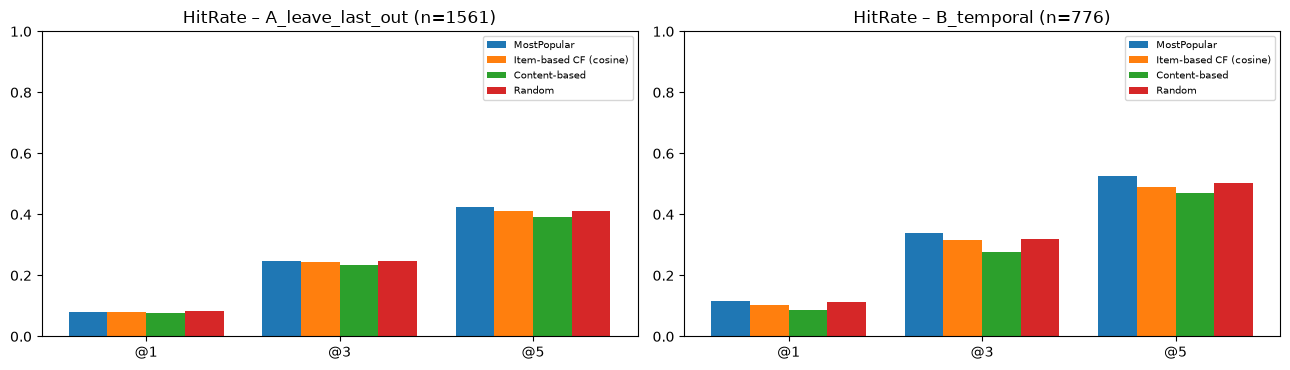

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, proto in zip(ax, results):
    t = results[proto]; w = 0.2
    for i, m in enumerate(t.index):
        a.bar(np.arange(len(KS)) + i * w, [t.loc[m, f"HitRate@{k}"] for k in KS], w, label=m)
    a.set_xticks(np.arange(len(KS)) + 1.5 * w); a.set_xticklabels([f"@{k}" for k in KS])
    a.set(title=f"HitRate – {proto} (n={ns[proto]['eligible_customers']})", ylim=(0, 1)); a.legend(fontsize=7)
fig.tight_layout(); plt.show()

## 4. Có quan hệ mua chung giữa các danh mục không? (ví dụ "mua CPU thì mua thêm RAM/SSD")

Đếm số khách mua cả hai danh mục rồi so với **kỳ vọng ngẫu nhiên** bằng permutation test: xáo danh mục giữa các đơn, **giữ nguyên số đơn mỗi khách và tần suất mỗi danh mục**. Cách này loại bỏ nhiễu "khách mua nhiều đơn thì tự nhiên mua nhiều danh mục". Có hiệu chỉnh Bonferroni cho 55 cặp.

In [26]:
def category_cooccurrence(ev: pd.DataFrame, n_perm=2000):
    """Quan sát: số khách mua cả hai danh mục. Null: xáo danh mục giữa các đơn (giữ nguyên số đơn mỗi khách
    và tần suất mỗi danh mục) -> kiểm soát việc khách mua nhiều đơn thì tự nhiên mua nhiều danh mục."""
    cats = sorted(ev.category_code.unique()); ci = {c: i for i, c in enumerate(cats)}
    cu = pd.factorize(ev.customer_id)[0]; cc = ev.category_code.map(ci).to_numpy()
    n_u, n_c = cu.max() + 1, len(cats)

    def cooc(cat_idx):
        inc = np.zeros((n_u, n_c)); inc[cu, cat_idx] = 1
        return inc.T @ inc
    obs = cooc(cc); rng = np.random.default_rng(SEED)
    sims = np.stack([cooc(rng.permutation(cc)) for _ in range(n_perm)])
    mu, sd = sims.mean(0), sims.std(0) + 1e-9
    z = (obs - mu) / sd
    p = (np.minimum((sims >= obs).sum(0), (sims <= obs).sum(0)) + 1) / (n_perm + 1) * 2
    rows = [dict(cat_a=cats[i], cat_b=cats[j], customers_both=int(obs[i, j]), expected_by_chance=round(mu[i, j], 1),
                 lift=round(obs[i, j] / mu[i, j], 3), z=round(z[i, j], 2), p_two_sided=min(1, p[i, j]))
            for i in range(n_c) for j in range(i + 1, n_c)]
    df = pd.DataFrame(rows)
    df["p_bonferroni"] = (df.p_two_sided * len(df)).clip(upper=1)
    return df.sort_values("p_two_sided"), cats, z


def repeat_purchase_check(ev: pd.DataFrame, n_perm=2000):
    """Khách có mua LẠI đúng sản phẩm cũ nhiều hơn ngẫu nhiên không? (permutation: xáo sản phẩm giữa các đơn,
    giữ nguyên số đơn mỗi khách và tần suất từng sản phẩm). Nếu có -> mở ra bài toán 'mua lại' thay vì 'mua mới'."""
    cu = pd.factorize(ev.customer_id)[0]; pi, uniq = pd.factorize(ev.product_id)
    n_u, n_p = cu.max() + 1, len(uniq)
    rep = lambda prod: int((np.bincount(cu * n_p + prod, minlength=n_u * n_p) > 1).sum())  # noqa: E731
    obs = rep(pi); rng = np.random.default_rng(SEED)
    sims = np.array([rep(rng.permutation(pi)) for _ in range(n_perm)])
    return {"observed_repeat_pairs": obs, "expected_by_chance": float(sims.mean()), "std": float(sims.std()),
            "z": float((obs - sims.mean()) / (sims.std() + 1e-9)), "p_one_sided": float(((sims >= obs).sum() + 1) / (n_perm + 1))}

Số cặp có ý nghĩa sau Bonferroni (p<0.05): 0 / 55


,cat_a,cat_b,customers_both,expected_by_chance,lift,z,p_two_sided,p_bonferroni
0,GPU,PERIPHERAL,406,374.9,1.083,2.48,0.014993,0.824588
1,CPU,PERIPHERAL,403,375.2,1.074,2.17,0.033983,1.000000
2,PERIPHERAL,PSU,249,228.0,1.092,1.99,0.062969,1.000000
3,HDD,MONITOR,119,133.1,0.894,-1.62,0.114943,1.000000
4,MOTHERBOARD,SSD,128,140.7,0.910,-1.43,0.179910,1.000000
5,PSU,RAM,151,140.0,1.079,1.23,0.234883,1.000000
6,CPU,RAM,241,228.1,1.057,1.24,0.244878,1.000000
7,CAMERA,HDD,120,130.5,0.919,-1.20,0.244878,1.000000


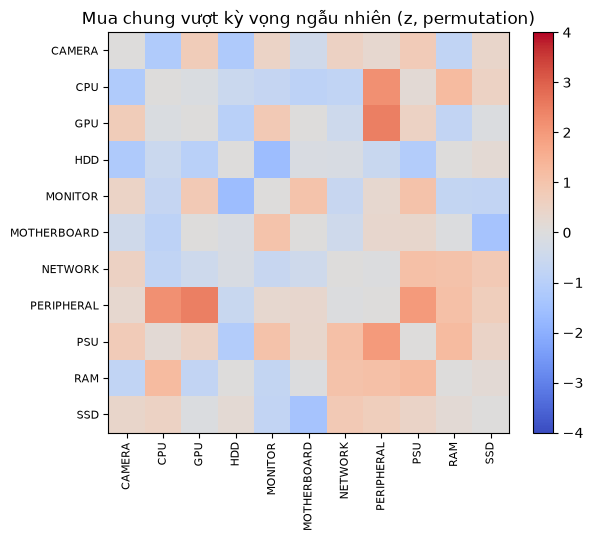

In [27]:
co, cats, z = category_cooccurrence(ev)
print("Số cặp có ý nghĩa sau Bonferroni (p<0.05):", int((co.p_bonferroni < 0.05).sum()), "/", len(co))
display(co.head(8).reset_index(drop=True))

zz = z.copy(); np.fill_diagonal(zz, 0)      # đường chéo (danh mục với chính nó) không có ý nghĩa
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(zz, cmap="coolwarm", vmin=-4, vmax=4)
ax.set_xticks(range(len(cats))); ax.set_xticklabels(cats, rotation=90, fontsize=8)
ax.set_yticks(range(len(cats))); ax.set_yticklabels(cats, fontsize=8)
ax.set_title("Mua chung vượt kỳ vọng ngẫu nhiên (z, permutation)"); fig.colorbar(im, fraction=.046); plt.show()

In [28]:
cpu = co[(co.cat_a == "CPU") | (co.cat_b == "CPU")].sort_values("lift", ascending=False)
display(cpu[["cat_a", "cat_b", "customers_both", "expected_by_chance", "lift", "z", "p_two_sided", "p_bonferroni"]].reset_index(drop=True))

,cat_a,cat_b,customers_both,expected_by_chance,lift,z,p_two_sided,p_bonferroni
0,CPU,PERIPHERAL,403,375.2,1.074,2.17,0.033983,1.0
1,CPU,RAM,241,228.1,1.057,1.24,0.244878,1.0
2,CPU,SSD,230,224.6,1.024,0.50,0.653673,1.0
3,CPU,PSU,224,222.1,1.009,0.18,0.927536,1.0
4,CPU,GPU,363,364.2,0.997,-0.10,0.948526,1.0
5,CPU,HDD,213,218.5,0.975,-0.53,0.632684,1.0
6,CPU,NETWORK,360,369.7,0.974,-0.76,0.472764,1.0
7,CPU,MONITOR,214,221.1,0.968,-0.67,0.552724,1.0
8,CPU,MOTHERBOARD,219,227.8,0.961,-0.85,0.422789,1.0
9,CAMERA,CPU,204,215.9,0.945,-1.19,0.262869,1.0


### Khách có mua *lại* đúng sản phẩm cũ nhiều hơn ngẫu nhiên không?

In [29]:
rep = repeat_purchase_check(ev)
pd.Series(rep).round(4)

observed_repeat_pairs    1204.0000
expected_by_chance       1178.0015
std                        22.8819
z                           1.1362
p_one_sided                 0.1239
dtype: float64

## 5. Danh sách gợi ý top-5 (Item-based CF) — chỉ để tham khảo

Cột `beats_baseline` chỉ `True` khi Item-CF vượt MostPopular **có ý nghĩa thống kê ở cả hai giao thức**.

In [30]:
R_all = interaction_matrix(ev, users, items)
Rb = (R_all > 0).astype(float); S_cf = cosine_similarity(Rb.T); np.fill_diagonal(S_cf, 0)
sc = Rb @ S_cf; rec = top_k(sc, Rb, 5)

recs = pd.DataFrame([{"customer_id": u, "rank": r + 1, "product_id": items.product_id[j], "product_name": items.product_name[j],
                      "score": round(float(sc[i, j]), 5)}
                     for i, u in enumerate(users) for r, j in enumerate(rec[i]) if np.isfinite(sc[i, j])])
beats = {p: any(r["significantly_better"] for b, r in verdicts[p]["Item-based CF (cosine)"].items() if b == "vs_MostPopular") for p in verdicts}
recs["beats_baseline"] = all(beats.values())
print("Item-CF vượt MostPopular có ý nghĩa ở từng giao thức:", beats)
recs.head(10)

Item-CF vượt MostPopular có ý nghĩa ở từng giao thức: {'A_leave_last_out': False, 'B_temporal': False}


,customer_id,rank,product_id,product_name,score,beats_baseline
0,KH000001,1,SP00007,Nguồn Corsair RM750e 750W,0.26852,False
1,KH000001,2,SP00001,Card màn hình RTX 4060 Ti,0.25325,False
2,KH000001,3,SP00014,Chuột Logitech G304,0.25149,False
3,KH000001,4,SP00015,Camera Hikvision DS-2CD,0.24964,False
4,KH000001,5,SP00006,RAM Kingston Fury 16GB DDR5,0.24614,False
5,KH000002,1,SP00009,Màn hình LG UltraGear 27inch,0.52390,False
6,KH000002,2,SP00010,CPU Intel Core i5-14600K,0.52244,False
7,KH000002,3,SP00002,Switch Cisco 24 Port,0.52000,False
8,KH000002,4,SP00001,Card màn hình RTX 4060 Ti,0.51189,False
9,KH000002,5,SP00006,RAM Kingston Fury 16GB DDR5,0.50126,False


## 6. Kết luận

**HitRate@3** (giao thức A: n = 1.561 khách · giao thức B: n = 776 khách)

| Mô hình | A | B |
|---|---|---|
| MostPopular | 0,247 | 0,339 |
| Item-based CF | 0,243 | 0,317 |
| Content-based | 0,235 | 0,276 |
| Random | 0,248 | 0,319 |

- **Không mô hình nào vượt MostPopular lẫn Random** ở cả hai giao thức. Content-based ở giao thức B còn *kém hơn* cả Random (khoảng tin cậy nằm hoàn toàn dưới 0).
- **0/55 cặp danh mục** có quan hệ mua chung có ý nghĩa sau Bonferroni; giả thuyết "mua CPU thì mua thêm RAM/SSD" không được dữ liệu ủng hộ.
- Khách **không** mua lại sản phẩm cũ nhiều hơn ngẫu nhiên (1.204 cặp quan sát so với ≈ 1.178 kỳ vọng).

**Hệ quả:** dữ liệu không có cấu trúc sở thích khách–sản phẩm để học. Theo đúng tinh thần tài liệu, nhóm nên **trình bày hạn chế này** thay vì cố làm recommendation cho đủ ba thuật toán, và không nên mở endpoint `/api/v1/recommendations` dựa trên kết quả này.

## 7. (Tuỳ chọn) Lưu kết quả

Đặt `SAVE = True` ở ô đầu để ghi ra thư mục `outputs/nb/` (cạnh notebook). Kết quả chính thức do `ml3_recommender.py` tạo (`--persist` để ghi vào `ml.product_recommendations`).

In [31]:
SAVE = True
if SAVE:
    out_dir = OUT_DIR; out_dir.mkdir(parents=True, exist_ok=True)   # OUT_DIR đã là outputs/nb
    for proto, t in results.items():
        t.round(5).to_csv(out_dir / f"ml3_metrics_{proto}.csv", encoding="utf-8-sig")
    co.to_csv(out_dir / "ml3_category_cooccurrence.csv", index=False, encoding="utf-8-sig")
    recs.to_csv(out_dir / "ml3_recommendations_top5.csv", index=False, encoding="utf-8-sig")
    print("Đã lưu vào", out_dir)
else:
    print("SAVE = False -> không ghi file.")

Đã lưu vào w:\Khánh\LAK_Khodulieu\mining\outputs\nb\ml3
